#### gumbel max trick

In [ ]:
### Gumbel max trick basic tests

import numpy as np
import scipy.special
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

L          = 16
x          = np.linspace(-1, 1, L)
rv         = multivariate_normal(0, 0.08)
base_distr = rv.pdf(x)
base_distr = base_distr / sum(base_distr)

total = np.zeros(16)
for i in range(100000):
    noise  = np.random.gumbel(size=16)
    argmax = scipy.special.softmax((np.log(base_distr) + noise) / 0.0001)
    total  = total + argmax

plt.figure()
_ = plt.bar(x, base_distr, width=0.1)

plt.figure()
_ = plt.bar(x, total, width=0.1)


#### soft NMS

In [ ]:
### Soft NMS test
import time
import numpy as np
import scipy.special
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

# create a number line
L = 100
x = np.linspace(-1, 1, L)

# create some gaussian blobs
z1 = multivariate_normal(-0.5, 0.01).pdf(x)
z2 = multivariate_normal(0.5, 0.5).pdf(x)

z1 /= z1.max()
z2 /= z2.max()

# true maximum
hard_z = np.maximum(z1, z2)[None, :]

# my pseudomax (with softmax)
z1z2 = np.concatenate([z1[None, :], z2[None, :]], axis=0)
temp = 0.2
soft_z = scipy.special.softmax(z1z2/temp, axis=0)
soft_z = np.sum(soft_z * z1z2, axis=0)

# exp norm maxiumum
logsumexp_z = scipy.special.logsumexp(z1z2, axis=0)

plt.figure()
_ = plt.scatter(x, hard_z, marker=".", color="green")
_ = plt.scatter(x, soft_z, marker=".", color="blue")
_ = plt.scatter(x, logsumexp_z, marker=".", color="red")

print(soft_z.max())


In [ ]:
def my_nms_looped(data, kernel_sz, softmax_temp=0.1, pad_mode="edge"):
    padded_data = np.pad(data, ((kernel_sz//2, kernel_sz//2)), mode=pad_mode)
    nms_out     = np.zeros(len(data))
    
    idx = 0
    while True:
        if (idx + kernel_sz) > len(padded_data):
            break
        
        kernel        = padded_data[idx:idx+kernel_sz]
        modified_temp = softmax_temp * np.std(kernel)
        soft_argmax   = scipy.special.softmax(kernel/modified_temp)
        nms_out[idx]  = soft_argmax[kernel_sz//2]
         
        idx += 1

    return nms_out
    
def my_nms_vectorized(data, kernel_sz, softmax_temp=0.2, pad_mode="edge"):
    padded_data = np.pad(data, (kernel_sz//2, kernel_sz//2), mode=pad_mode)
    
    # Extract sliding windows using as_strided
    shape           = (len(soft_z), kernel_sz)
    strides         = (padded_data.strides[0], padded_data.strides[0])
    sliding_windows = np.lib.stride_tricks.as_strided(padded_data, shape=shape, strides=strides)
    
    # Apply softmax across each window
    modified_temp = softmax_temp * np.std(sliding_windows, axis=1)[:, None]
    soft_maximums = scipy.special.softmax(sliding_windows/modified_temp, axis=1)
    
    # Take the center value (middle index of each softmax window)
    nms_out = soft_maximums[:, kernel_sz//2]
    
    return nms_out

temp = 0.1
KS   = 15
data = soft_z + np.random.randn(soft_z.shape[0])*0.02

plt.figure()
_ = plt.scatter(x, data, marker=".", color="blue")
_ = plt.scatter(x, my_nms_looped(data, kernel_sz=KS, softmax_temp=temp), marker="o", color="firebrick")
_ = plt.scatter(x, my_nms_vectorized(data, kernel_sz=KS, softmax_temp=temp), marker=".", color="darkorange")

In [ ]:
import scipy.ndimage

temp = 0.1
data = soft_z + np.random.randn(soft_z.shape[0])*0.02
ks   = 3

N = 200
nms_collection = np.zeros((N, 100))
sigmas = np.linspace(0, 1, N) * 25

for i in range(N):
    
    smooth_data = scipy.ndimage.gaussian_filter(data, sigma=sigmas[i])
    nms = my_nms_vectorized(smooth_data, kernel_sz=ks, softmax_temp=temp)
    nms_collection[i, :] = nms



plt.figure(figsize=(10, 10))
plt.imshow(nms_collection)

plt.figure()
plt.imshow(np.sum(nms_collection, axis=0)[None, :])


In [ ]:
N = 1000

t0 = time.time()
for i in range(N):
    _ = my_nms_looped(soft_z, kernel_sz=15, softmax_temp=0.2)
t1 = time.time()
t_looped = t1-t0

t0 = time.time()
for i in range(N):
    _ = my_nms_vectorized(soft_z, kernel_sz=15, softmax_temp=0.2)
t1 = time.time()
t_vectorized = t1-t0


print(f"time looped:     {t_looped/N:.5f}s")
print(f"time vectorized: {t_vectorized/N:.5f}s")
print(f"time gain:       {t_looped / t_vectorized:.2f} times faster")

#### 2d gaussians

0.18974452241991063


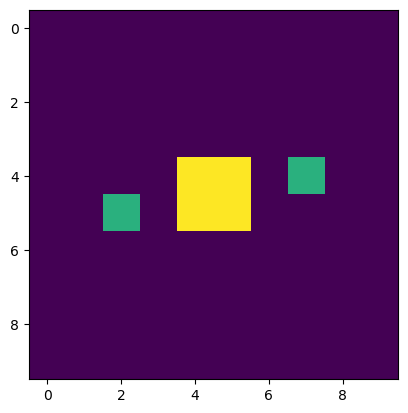

In [119]:
import time
import numpy as np
import scipy.special
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

def nms_vec_2d(data: np.ndarray, kernel_sz: int, softmax_temp: float=0.1, pad_mode: str="edge"):
    padded_data = np.pad(data, ((kernel_sz//2, kernel_sz//2), (kernel_sz//2, kernel_sz//2)), mode=pad_mode)
        
    # Extract sliding windows using as_strided
    shape           = (data.shape[0], data.shape[1], kernel_sz, kernel_sz)
    strides         = (padded_data.strides[0], padded_data.strides[1], padded_data.strides[0], padded_data.strides[1])
    sliding_windows = np.lib.stride_tricks.as_strided(padded_data, shape=shape, strides=strides)
    windows_flat    = sliding_windows.reshape(sliding_windows.shape[0], sliding_windows.shape[1], -1)

    # Apply softmax across each window
    modified_temp = softmax_temp * np.std(windows_flat, axis=-1)[:, :, None]
    soft_maximums = scipy.special.softmax(windows_flat/modified_temp, axis=2)
    
    # Take the center value (middle index of each softmax window)
    nms_out = soft_maximums[:, :, (kernel_sz**2)//2]
    
    return nms_out


N = 10
x, y = np.linspace(-1, 1, N), np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, y)
pos  = np.stack([X, Y], axis=2)

rv1 = multivariate_normal(np.array([ 0,   0]), np.array([[0.1, 0], [0, 0.1]]))
rv2 = multivariate_normal(np.array([-0.6, 0.01]), np.array([[0.01, 0], [0, 0.01]]))
rv3 = multivariate_normal(np.array([ 0.6, -0.01]), np.array([[0.01, 0], [0, 0.01]]))

Z1 = rv1.pdf(pos)/rv1.pdf(pos).max()
Z2 = rv2.pdf(pos)/rv2.pdf(pos).max()
Z3 = rv3.pdf(pos)/rv3.pdf(pos).max()

temp = 0.2
Z = np.stack([Z1, Z2, Z3], axis=2)
Z = scipy.special.softmax(Z/temp, axis=2) * Z
Z = np.sum(Z, axis=2)

nms = nms_vec_2d(Z, kernel_sz=15, softmax_temp=0.1)
plt.imshow(nms)

print(nms.max())



In [105]:
### test asymmetric sinkhorn with specified marignals

def sinkhorn_log_normalization(mtx_cost, row_marginal, col_marginal, temp=0.2, n_iter=20):
    """
    Perform Sinkhorn normalization in log-space with custom row and column marginals.

    Args:
        mtx_cost (np.ndarray): Cost matrix (analogous to logits), shape (m, n).
        row_marginal (np.ndarray): Desired marginal sums for rows (length m).
        col_marginal (np.ndarray): Desired marginal sums for columns (length n).
        temp (float): Temperature parameter.
        n_iter (int): Number of Sinkhorn iterations.
    
    Returns:
        np.ndarray: Sinkhorn-normalized matrix (in probability space).
    """
    assert mtx_cost.ndim == 2, "Cost matrix must be 2D"
    assert len(row_marginal) == mtx_cost.shape[0], "Row marginal must match matrix rows"
    assert len(col_marginal) == mtx_cost.shape[1], "Column marginal must match matrix columns"
    assert np.isclose(np.sum(row_marginal), np.sum(col_marginal)), "Marginals must sum to the same value"
    
    # Initialize the kernel in log-space (negative cost over temperature)
    log_kernel = - mtx_cost / temp

    # Log-space marginals
    log_row_marginal = np.log(row_marginal)
    log_col_marginal = np.log(col_marginal)

    for _ in range(n_iter):
        # Row normalization (logsumexp across axis 1)
        log_kernel -= scipy.special.logsumexp(log_kernel, axis=1, keepdims=True)
        log_kernel += log_row_marginal[:, None]  # Apply row marginal
        
        # Column normalization (logsumexp across axis 0)
        log_kernel -= scipy.special.logsumexp(log_kernel, axis=0, keepdims=True)
        log_kernel += log_col_marginal[None, :]  # Apply column marginal
    
    # Return the exponentiated matrix (probability distribution)
    return np.exp(log_kernel)


cost_mtx = np.array([
    [1, 5, 0],
    [5, 1, 0],
    [9, 9, 0],
    [9, 9, 0],
    [9, 9, 0],
])

perm = sinkhorn_log_normalization(cost_mtx, row_marginal=np.array([1, 1, 1, 1, 1]), col_marginal=np.array([1, 1, 3]))

display(perm.round(decimals=2))

array([[1.  , 0.  , 0.03],
       [0.  , 1.  , 0.03],
       [0.  , 0.  , 0.98],
       [0.  , 0.  , 0.98],
       [0.  , 0.  , 0.98]])

#### generate random covariances

0.9185521450069021


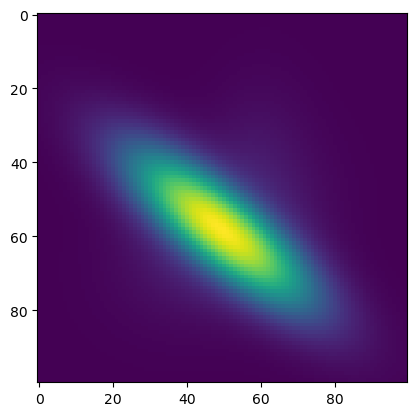

In [484]:
N = 100
L = 2
x, y = np.linspace(-L, L, N), np.linspace(-L, L, N)
X, Y = np.meshgrid(x, y)
pos  = np.stack([X, Y], axis=2)

n_blobs = 3
Z = np.zeros((N, N, n_blobs))
for i in range (n_blobs):
    sigma = np.array([
        [np.random.rand(),                0],
        [               0, np.random.rand()],
        ])

    alpha = np.random.rand() * 2 * np.pi
    rotmat = np.array([
        [np.cos(alpha), -np.sin(alpha)],
        [np.sin(alpha),  np.cos(alpha)],
        ])

    covar = rotmat.T @ sigma @ rotmat

    mean  = (np.random.rand(2) - 0.5)
    stren = np.random.rand()
    
    rv  = multivariate_normal(mean, covar)
    Z[:, :, i] = (rv.pdf(pos) / rv.pdf(pos).max()) * stren


temp = 0.2
Z = np.sum(scipy.special.softmax(Z/temp, axis=2) * Z, axis=2)
_ = plt.imshow(Z)
print(Z.max())


#### deconvolution

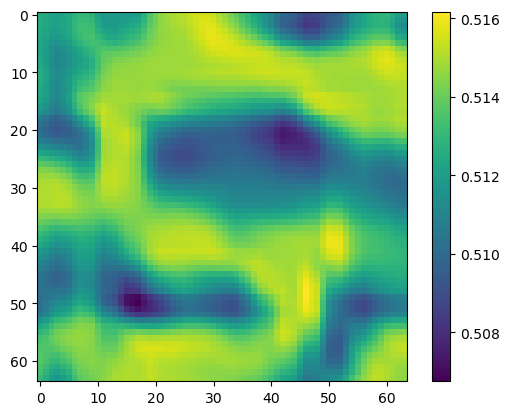

In [388]:
import torch
import matplotlib.pyplot as plt

activ = torch.nn.LeakyReLU()
conv1 = torch.nn.Conv2d(2, 2, kernel_size=3, stride=1, padding=0)
conv2 = torch.nn.Conv2d(2, 2, kernel_size=3, stride=1, padding=0)
conv3 = torch.nn.Conv2d(2, 1, kernel_size=3, stride=1, padding=0)

BS = 3
x = torch.rand(BS, 128)
x = x.view(BS, 2, 8, 8)

# upsample
x = torch.nn.functional.interpolate(x, size=16+2, mode="bilinear")
x = activ(conv1(x))
x = torch.nn.functional.interpolate(x, size=32+2, mode="bilinear")
x = activ(conv2(x))
x = torch.nn.functional.interpolate(x, size=64+2, mode="bilinear")
x = conv3(x)
x = torch.nn.functional.sigmoid(x)

# plot
plt.figure()
plt.imshow(x[0, 0].detach())
plt.colorbar()
